# Hypothesis testing

We want to investigate whether total sleep duration and maximum lifespan in mammals are linearly related.

- H$_0$: the slope of the linear regression is zero ($\beta_1=0$).
- H$_1$: the slope of the linear regression is not zero ($\beta_1\neq0$).

We use a two-sided test with a significance threshold of 0.05.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

df = pd.read_csv("dataset_2191_sleep.csv")
df = df[['total_sleep', 'max_life_span']].copy()

# Convert invalid or missing entries to NaN
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.replace([np.inf, -np.inf], np.nan).dropna(how='any')
x = df['total_sleep'].to_numpy(dtype=float)
y = df['max_life_span'].to_numpy(dtype=float)
print("Sample size:", len(x))

Sample size: 54


## Hypothesis test

We use `stats.linregress` to test whether the slope differs from zero.

In [2]:
results = stats.linregress(x, y)
print(results)
print("p-value:", results.pvalue)

alpha = 0.05
p_value = results.pvalue
if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

LinregressResult(slope=np.float64(-1.6403372989524587), intercept=np.float64(36.93262339261051), rvalue=np.float64(-0.41020238875955006), pvalue=np.float64(0.0020655490888052187), stderr=np.float64(0.5057379350371508), intercept_stderr=np.float64(5.769580251262744))
p-value: 0.0020655490888052187
Reject the null hypothesis.


## Bootstrapping

Following the example notebook, we resample paired observations with replacement to estimate 95% confidence intervals for the slope and intercept.

In [3]:
def linear_regression(x, y):
    results = stats.linregress(x, y)
    return results.slope, results.intercept

a, b = linear_regression(x, y)

res = stats.bootstrap((x, y), linear_regression,
                      confidence_level=0.95, paired=True,
                      vectorized=False, random_state=42)
conf_int = res.confidence_interval
low = conf_int.low
high = conf_int.high

print("slope:     ", a, "[", low[0], ",", high[0], "]")
print("intercept: ", b, "[", low[1], ",", high[1], "]")
print("p-value:   ", p_value)

slope:      -1.6403372989524587 [ -2.581668915363359 , -0.8524671699295182 ]
intercept:  36.93262339261051 [ 26.77660358821135 , 51.05134586926938 ]
p-value:    0.0020655490888052187


## Visualisation of the regression

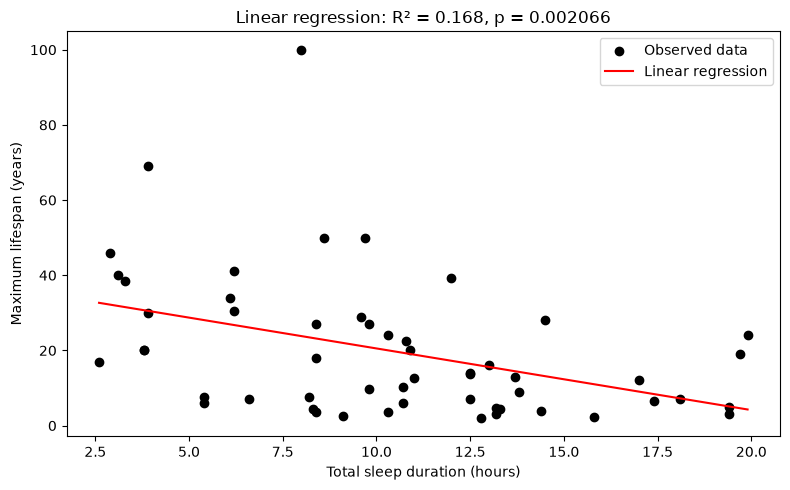

In [4]:
x_line = np.linspace(min(x), max(x), 100)
y_line = a * x_line + b

plt.figure(figsize=(8, 5))
plt.scatter(x, y, c='k', label='Observed data')
plt.plot(x_line, y_line, color='red', label='Linear regression')
plt.xlabel('Total sleep duration (hours)')
plt.ylabel('Maximum lifespan (years)')
plt.title(f'Linear regression: R² = {results.rvalue**2:.3f}, p = {p_value:.4g}')
plt.legend()
plt.tight_layout()
plt.show()

## Visualisation of parameter uncertainty

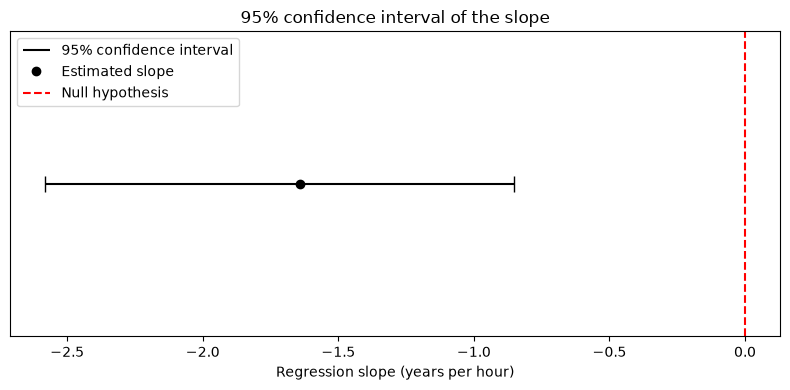

In [5]:
plt.figure(figsize=(8, 4))
plt.hlines(0, low[0], high[0], color='black', label='95% confidence interval')
plt.plot([low[0], high[0]], [0, 0], '|', color='black', markersize=12)
plt.plot(a, 0, 'ko', label='Estimated slope')
plt.axvline(0, color='red', linestyle='--', label='Null hypothesis')
plt.xlabel('Regression slope (years per hour)')
plt.title('95% confidence interval of the slope')
plt.yticks([])
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

A p-value below 0.05 provides evidence against the null hypothesis. If the bootstrap confidence interval excludes zero, it also supports a nonzero slope. The two methods need not always agree.

The slope describes the estimated change in maximum lifespan per additional hour of sleep. This is an association, not evidence of causation. The conventional slope test assumes independent observations, a linear mean relationship, constant residual variance and approximately normal errors. Shared evolutionary ancestry and omitted variables such as body mass may limit interpretation. This analysis uses all cleaned observations and is exploratory if the hypothesis was formulated after inspecting the data.

In [ ]:
print(f"Slope: {a:.4f} years per hour")
print(f"95% bootstrap CI: [{low[0]:.4f}, {high[0]:.4f}]")
print(f"p-value: {p_value:.6g}")
if p_value < alpha:
    direction = 'negative' if a < 0 else 'positive'
    print(f"There is statistically significant evidence of a {direction} linear relationship.")
else:
    print("There is insufficient evidence of a nonzero linear slope.")